In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split



from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models


In [9]:
df = pd.read_csv("/content/sample_data/mnist_train_small.csv")
df_test = pd.read_csv("/content/sample_data/mnist_test.csv")


In [10]:

df.head()

,6,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,...,0.581,0.582,0.583,0.584,0.585,0.586,0.587,0.588,0.589,0.590
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [11]:
df.shape


(19999, 785)

In [12]:

df.columns

Index(['6', '0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8',
       ...
       '0.581', '0.582', '0.583', '0.584', '0.585', '0.586', '0.587', '0.588',
       '0.589', '0.590'],
      dtype='object', length=785)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19999 entries, 0 to 19998
Columns: 785 entries, 6 to 0.590
dtypes: int64(785)
memory usage: 119.8 MB


In [7]:
df.isnull().sum()

,0
6,0
0,0
0.1,0
0.2,0
0.3,0
...,...
0.586,0
0.587,0
0.588,0
0.589,0


In [14]:
# Separate features and target

X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

# Normalize pixel values
X = X / 255.0

# Train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
# Reshape data for CNN

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (15999, 28, 28, 1)
Testing shape: (4000, 28, 28, 1)


In [16]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

In [18]:
model = Sequential([

    Conv2D(32, (3,3), activation='relu',
           input_shape=(28,28,1)),

    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),

    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(10, activation='softmax')
])

In [19]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [20]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.8788 - loss: 0.3861 - val_accuracy: 0.9678 - val_loss: 0.1032
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.9645 - loss: 0.1182 - val_accuracy: 0.9744 - val_loss: 0.0847
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.9730 - loss: 0.0814 - val_accuracy: 0.9725 - val_loss: 0.0796
Epoch 4/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9797 - loss: 0.0649 - val_accuracy: 0.9809 - val_loss: 0.0685
Epoch 5/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9840 - loss: 0.0498 - val_accuracy: 0.9850 - val_loss: 0.0550
Epoch 6/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9862 - loss: 0.0419 - val_accuracy: 0.9866 - val_loss: 0.0502
Epoch 7/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.9891 - loss: 0.0322 - val_accuracy: 0.9869 - val_loss: 0.0514
Epoch 8/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9908 - loss: 0.0269 - 

In [22]:

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

Test Accuracy: 0.9832500219345093
Test Loss: 0.059759821742773056


In [23]:
y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

print(y_pred_classes[:10])

125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
[2 9 8 8 0 1 0 7 1 2]


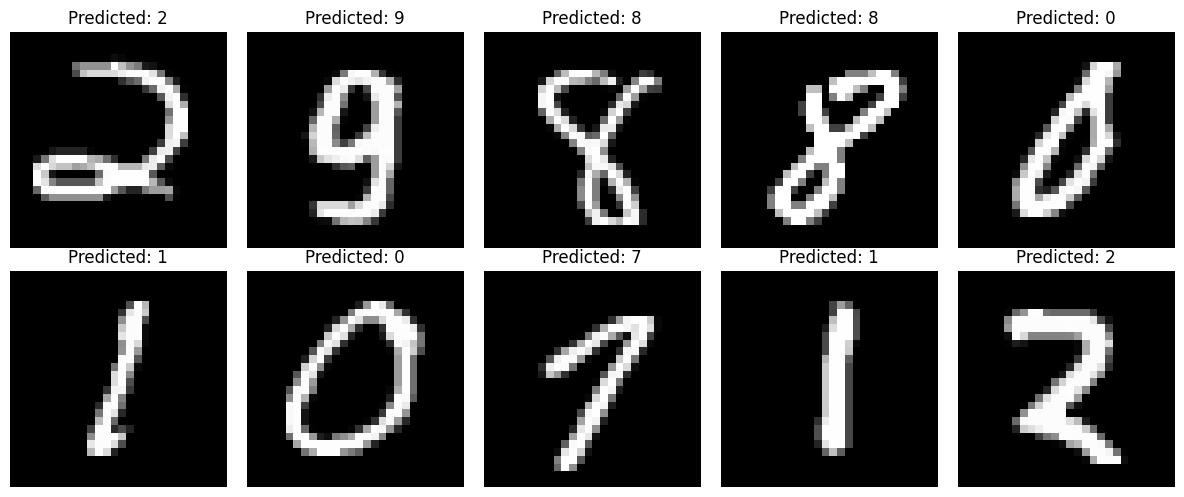

In [24]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {y_pred_classes[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [25]:
model.save("mnist_cnn_model.keras")

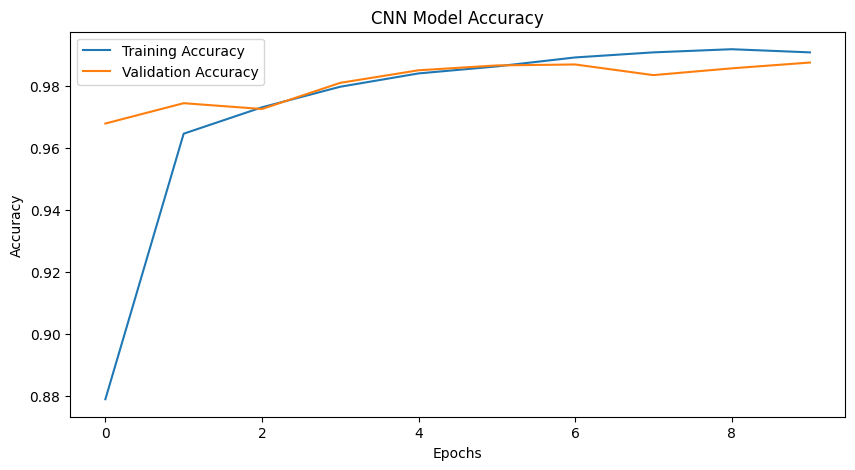

In [26]:
plt.figure(figsize=(10,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

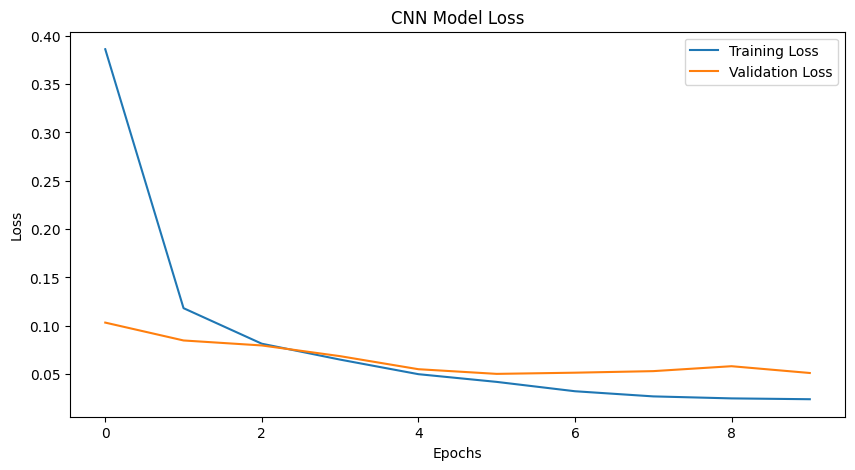

In [27]:
plt.figure(figsize=(10,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [28]:
from google.colab import files
files.download("mnist_cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>